# Simulation of Faraday rotation SAOCOM

In [1]:
'''
File Name: pol_simulate_FR_image_saocom.ipynb

Authors:
    Juan M. Lopez-Sanchez  
    University of Alicante

Date: July 2025

Description:
------------
This script computes the result of injecting a one-way Faraday rotation 
angle to a dual-pol (VV-VH) SAOCOM image and provides the resulting RGB image.

The original image must have been previously processed and should be available 
in POL format (either as COV or GCOV).

Dependencies:
-------------
- numpy
- os
- PIL
- tqdm
- rosel.io
- rosel.computation
- rosel.shiroma

Usage:
------
To use this script, define the following parameters:
    
    - common_folder: Common path to all products, e.g. '/media/s3-ard-rose-l/PHASE_1/DEMONSTRATOR'
    - site: 'Naples', 'Salamanca', or 'BlackForest'
    - orbit: 'ASC' or 'DSC'
    - beam: 'S3' or 'S4' 
    - multilook_option: 'SHIROMA' (without multi-look) or 'MULTI-LOOK'
    - multilook_size: e.g. '9x5', '11x7', 15x9', etc. Not used if multilook_option is 'SHIROMA' 
    - product: 'COV' or 'GCOV'
    - Omega: One-way FR angle (degrees), e.g. 10
    - acquisition_date: time stamp of the original product, from with the date is used, e.g. '2021-02-28T17:09:09.724349' # Available for DSC/S4 Naples
'''


"\nFile Name: pol_simulate_FR_image_saocom.ipynb\n\nAuthors:\n    Juan M. Lopez-Sanchez  \n    University of Alicante\n\nDate: July 2025\n\nDescription:\n------------\nThis script computes the result of injecting a one-way Faraday rotation \nangle to a dual-pol (VV-VH) SAOCOM image and provides the resulting RGB image.\n\nThe original image must have been previously processed and should be available \nin POL format (either as COV or GCOV).\n\nDependencies:\n-------------\n- numpy\n- os\n- PIL\n- tqdm\n- rosel.io\n- rosel.computation\n- rosel.shiroma\n\nUsage:\n------\nTo use this script, define the following parameters:\n\n    - common_folder: Common path to all products, e.g. '/media/s3-ard-rose-l/PHASE_1/DEMONSTRATOR'\n    - site: 'Naples', 'Salamanca', or 'BlackForest'\n    - orbit: 'ASC' or 'DSC'\n    - beam: 'S3' or 'S4' \n    - multilook_option: 'SHIROMA' (without multi-look) or 'MULTI-LOOK'\n    - multilook_size: e.g. '9x5', '11x7', 15x9', etc. Not used if multilook_option is 'S

Package dependencies

In [2]:
import numpy as np
import rosel.io
import rosel.computation
import rosel.shiroma


import os
import pathlib

from tqdm import tqdm
import matplotlib.pyplot as plt
from PIL import Image

Auxiliary functions

1) Generation of an RGB image from dual-pol data

In [3]:

def bytescl( data, lim, mask = None ):
    
    data_val = np.clip( (data - lim[0]) / (lim[1] - lim[0]), 0, 1)
                
    data_byte = np.zeros_like( data_val, dtype=np.uint8)
    
    if mask is None:
           data_byte[:] = 255 * data_val[:]
    else:
           data_byte[mask] = 255 * data_val[mask]
    
    return data_byte

def show_rgb_C2( C11, C22, C12 ):
    
    # Show an RGB image from C11 and C22.
    # C12 is not used.
    
    Nrows, Ncols = C11.shape
    
    # dB scale
    
    C11_dB = 10*np.log10( C11 + 1e-12)
    C22_dB = 10*np.log10( 2*C22 + 1e-12)
    CH_dB =  10*np.log10( C11 / (C22 + 1e-12) + 1e-12)
    
    # Dynamic range
    
    mindB = -25
    maxdB = 5
    mindif = 0
    maxdif = 20
    
    # Create the RGB image
    
    RGB_image = np.zeros([Nrows, Ncols, 3], dtype=np.uint8)
    
    RGB_image[:,:,0] = bytescl( C11_dB, [mindB, maxdB]) # R
    RGB_image[:,:,1] = bytescl( C22_dB, [mindB, maxdB])  # G
    RGB_image[:,:,2] = bytescl( CH_dB, [mindif, maxdif]) # B

    return RGB_image


2) Injection of Faraday Rotation on dual-pol data (C2 covariance matrix)

In [4]:
def inject_FaradayRotation_dualpol( C2, Omega_deg ):

    # Inputs:
    #  - C2: Dual-pol covariance matrix expressed as an array with three values: [C11, C22, C12]
    #  - Omega_deg: one-way Faraday rotation angle (degrees)
    #
    # Output:
    #  - C2out: Dual-pol covariance matrix expressed as an array with three values: [C11, C22, C12]

    # Convert angle to radians
    
    Omega = Omega_deg*np.pi/180.0

    # Extract input values from C2
    
    s0VV = C2[0]    
    s0VH = C2[1]
    
    rho = C2[2] / np.sqrt( s0VV * s0VH )
    
    rho_cox = np.abs( rho )
    phase_cox = np.angle( rho )
    
    # Assumptions (they depend on the actual scene, but are unknown in dual-pol)
    
    s0HH = s0VV
    rho_co = 0.5 
    phase_co = 0 # degrees
    
    # Distortion induced by Faraday rotation
    
    cosO = np.cos(Omega)
    sinO = np.sin(Omega)
    
    C_11_FR = cosO**4 * s0VV + sinO**4 * s0HH - 2 * sinO**2 * cosO**2 * np.sqrt(s0VV*s0HH) * rho_co * np.cos(phase_co) 
    
    C_22_FR = s0VH + sinO**2 * cosO**2 * ( s0HH + s0VV + 2 * np.sqrt(s0VV*s0HH) * rho_co * np.cos(phase_co) ) \
                - sinO * cosO * ( 2 * np.sqrt(s0HH*s0VH) * rho_cox * np.cos(phase_cox) + 2 * np.sqrt(s0VV*s0VH) * rho_cox * np.cos(phase_cox) )
    
    C_12_FR = sinO**3 * cosO * ( s0HH +  np.sqrt(s0VV*s0HH) * rho_co * np.exp(-1j*phase_co) ) \
                - sinO * cosO**3 * ( s0VV +  np.sqrt(s0VV*s0HH) * rho_co * np.exp(1j*phase_co) ) \
                + cosO**2 * np.sqrt(s0VV*s0VH) * rho_cox * np.exp(1j*phase_cox) \
                - sinO**2 * np.sqrt(s0HH*s0VH) * rho_cox * np.exp(1j*phase_cox)
                
    C2out = [ C_11_FR, C_22_FR, C_12_FR ]
    
    return C2out

User-defined input parameters 

In [5]:
########################
# PARAMETERS
########################

common_folder = '/s3/bopen-sar/ARD-ROSE-L/PHASE_1/DEMONSTRATOR/'

site = 'Naples' # Naples, Salamanca, BlackForest
orbit = 'DSC'   # ASC, DSC
beam = 'S4'      # S3, S4

multilook_option = 'MULTI-LOOK' # 'SHIROMA' (wthiout multi-look) or 'MULTI-LOOK'
multilook_size = '11x7' # e.g. '9x5', '11x7', 15x9'. Not used if multilook_option is 'SHIROMA'

product = 'GCOV' # 'COV' or 'GCOV'

Omega = 10 # one-way FR angle (degrees)

# Date selection
# Example:
acquisition_date = '2021-02-28T17:09:09.724349' # Available for DSC/S4 Naples

Definition of input folder with the POL product to be used (by means of the user-defined parameters)

In [6]:
# Date format (as subfolder of POL products)

date_txt = acquisition_date[:10] # only the string with the date

# Form path to input POL product

polsar_folder = os.path.join( common_folder, 'POL', site, orbit, beam, multilook_option)

if multilook_option == 'MULTI-LOOK':
    polsar_folder = os.path.join( polsar_folder, multilook_size)

input_folder = os.path.join( polsar_folder, date_txt )

PROCESSING

In [7]:

# Read the 3 layers of a POL product

C11 = rosel.io.read( os.path.join( input_folder, product, 'C11'), consolidate_metadata = False ).v
C22 = rosel.io.read( os.path.join( input_folder, product, 'C22'), consolidate_metadata = False ).v
C12 = rosel.io.read( os.path.join( input_folder, product, 'C12'), consolidate_metadata = False ).v

In [8]:

# Prepare the output product layers as numpy arrays

Nrows, Ncols = C11.shape

C11F = np.array( np.abs(C11) ).astype(np.float32)
C22F = np.array( np.abs(C22) ).astype(np.float32)
C12F = np.array( C12 ).astype(np.complex64)

# Inject FR at each pixel

for ir in tqdm(range(0, Nrows)):
       
    for ic in range(Ncols):
        
        if ~np.isnan(C11F[ir,ic]):
                   
            C2F = inject_FaradayRotation_dualpol( [C11F[ir,ic], C22F[ir,ic], C12F[ir,ic]], Omega )
            
            C11F[ir,ic] = C2F[0]
            C22F[ir,ic] = C2F[1]
            C12F[ir,ic] = C2F[2]

100%|██████████| 10323/10323 [20:48<00:00,  8.27it/s] 


In [9]:

# RGB representation (using only the intensities of the two channels)
image = show_rgb_C2( C11F, C22F, C12F )

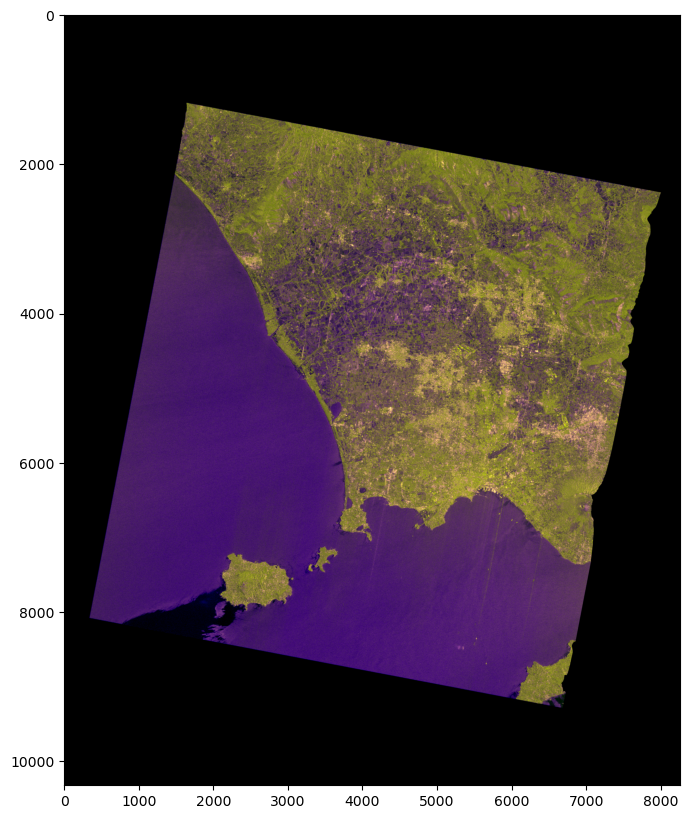

In [10]:
plt.figure(figsize=(10,10))
plt.imshow( image )
plt.show()